# Attribution maps of the MEGAN emission change, exact split (LMDI), PD and FUT

Same figure as `megan_factor_maps.ipynb` → `PD_<group>_attribution_<season>_*.png` (Δln E split into composition and the MEGAN activity factors), but with the **exact LMDI split** of the branch runs (`analysis/MEGAN_ATTRIBUTION.md` option 1) instead of the grid-cell area-mean factors. Why: `megan-lmdi-vs-approx.ipynb` §6 shows the area-mean split gets composition and γ_L with the wrong sign.

| | Old maps (approx.) | These maps (LMDI) |
|---|---|---|
| Input | processed h0 of CTRL_P / LCC_P | `data/processed-data/megan-lmdi/megan_lmdi_<PD|FUT>_<year>.nc` only |
| Years | 2001–2014 (or 2001–2025) | **2001, 2002, 2005, 2006, 2010, 2011** (6 years) |
| Row 1 | Δln E = Δln(f·ε) + Δln γ_eff | Δln E = composition (w·ε) + activity (Σ γ_i) + CLM safeguard |
| Row 2 | Δln γ_eff ≈ Σ Δln γ_i (area means) | activity = Σ γ_i **exactly** |
| Row 3 | residual = weighting + co-variation | — (no residual by construction) |

**Units.** Per cell, LMDI contributions C_f (kg m⁻² s⁻¹) are put in 100·Δln units by 100·Δln E · C_f / ΔE, so the panels add up to 100·Δln E in every cell and year. **Composition** = change of the patch weights w·ε of matched patches (same cell + PFT) + the whole emission of patches present in one run only; not identical to the old f·ε. **CLM safeguard** = steps where CLM sets MEG = 0 because the total γ is outside [0, 100) (+ 'unexplained', which is 0).

**FUT** (LCC_FUT vs CTRL_FUT) is drawn only when all 6 FUT years are reduced; until then it is skipped (`cases-scripts/run_when_done/megan_lmdi_maps_when_FUT_done.sh` reruns this notebook when they are).

Same conventions as the old maps: one colour scale ±60 (PD) / ±100 (FUT), cells with CTRL emission < 1 % of the 98th percentile ≥ 45°N masked, under the maps the CTRL-emission-weighted mean 45–90°N ± 95 % t-interval of the 6 yearly means, hatched = not FDR-significant (paired t-test over the 6 years, α_FDR = 0.10), dashed = modified cells. Season means are step-weighted (`nsteps`).

**2001 and 2002** come from the hybrid-start chain, whose first PD reduction shifted the months by one 30-min step (≤ 0.3 %, `megan-lmdi-vs-approx.ipynb` §2). Fixed in `reduce_megan_lmdi.py` (user 2026-11-15, each step in the month of its own stamp); PD 2001/2002 re-reduced, FUT reduced with the fixed code. The files' `month_assignment` attribute is printed below.

Outputs: `results/figures/megan_factors/<PD|FUT>_<group>_attribution_LMDI_<season>_6yr.png`, tables `results/tables/megan_factors/megan_lmdi_attribution_<PD|FUT>_45N.csv`.

## 1. Setup and loading

In [1]:
import sys
from pathlib import Path
REPO = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION")
sys.path.insert(0, str(REPO / "src"))
import time
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from IPython.display import display
from boreal_forest_expansion.plotting import megan_maps as mm, forcing_maps as fm
from boreal_forest_expansion.plotting.style import set_default_style

set_default_style()
LMDI_DIR = REPO / "data/processed-data/megan-lmdi"
YEARS = [2001, 2002, 2005, 2006, 2010, 2011]
GROUPS = ["isoprene", "MTERP"]
SEASONS = ["ANN", "JJA"]
LAT_MIN = 45.0
FDR_ALPHA = 0.10
MIN_EMISSION_SHARE = 0.01
GAMMAS = ["gammaL", "gammaT", "gammaP", "gammaA", "gammaC"]
FIG = REPO / "results/figures/megan-lmdi-attribution-maps"   # layout 2026-11-16
FIG.mkdir(parents=True, exist_ok=True)
TAB = REPO / "results/tables/megan-lmdi-attribution-maps"
TAB.mkdir(parents=True, exist_ok=True)

TITLE = {
    "dlnE": "EMISSION\nΔln E", "composition": "COMPOSITION\nΔln(w·ε)", "activity": "ACTIVITY\nΣ Δln γ$_i$",
    "safeguard": "CLM SAFEGUARD\nMEG set to 0", "gammaL": "LAI\nΔln γ$_L$", "gammaT": "TEMPERATURE\nΔln γ$_T$",
    "gammaP": "LIGHT\nΔln γ$_P$", "gammaA": "LEAF AGE\nΔln γ$_A$", "gammaC": "CO$_2$\nΔln γ$_C$",
}

EXPERIMENTS = {   # experiment: (case prefix of the meganpatch branches, LCC alias, CTRL alias)
    "PD": ("NF2000norbc_tropstratchem_nudg_", "LCC_PD", "CTRL_PD"),
    "FUT": ("NF2100ssp585norbc_tropstratchem_nudg_", "LCC_FUT", "CTRL_FUT"),
}

def load_experiment(exp):
    prefix = EXPERIMENTS[exp][0]
    out = {}
    for y in YEARS:
        f = LMDI_DIR / f"megan_lmdi_{exp}_{y}.nc"
        for attempt in range(3):          # NIRD reads fail now and then (NetCDF: HDF error); retry
            try:
                with xr.open_dataset(f) as raw:
                    raw[["nsteps", "E_ctrl", "E_lcc", "contribution"]].load()
                break
            except RuntimeError as exc:
                print(f"{f.name}: read failed ({exc}), retry {attempt + 1}")
                time.sleep(30)
        with xr.open_dataset(f) as raw:
            attrs = raw.attrs
            ds = raw[["nsteps", "E_ctrl", "E_lcc", "contribution"]]
            ds = ds.assign_coords(compound=attrs["compounds"].split(","), factor=attrs["factors"].split(","),
                                  month=ds["month"].values % 100)
            assert attrs["ctrl_case"].startswith(prefix + "ctrl_meganpatch"), attrs["ctrl_case"]
            assert attrs["lcc_case"].startswith(prefix + "lcc_meganpatch"), attrs["lcc_case"]
            assert list(ds["month"].values) == list(range(1, 13))
            assert "fail" not in attrs["checks"].lower()
            out[y] = ds.sel(lat=slice(LAT_MIN - 5, None)).load()
        print(exp, y, attrs["ctrl_case"], "/", attrs["lcc_case"], "| month_assignment:", attrs.get("month_assignment", "-")[:60])
    return out

lm = {}
for exp in EXPERIMENTS:
    missing = [y for y in YEARS if not (LMDI_DIR / f"megan_lmdi_{exp}_{y}.nc").exists()]
    if missing:
        print(f"{exp}: SKIPPED, years not reduced yet: {missing}")
        continue
    lm[exp] = load_experiment(exp)
assert "PD" in lm


PD 2001 NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2000 / NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261105-from2000 | month_assignment: step month = month of its own stamp (00:00 -> previous day);
PD 2002 NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2000 / NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261105-from2000 | month_assignment: step month = month of its own stamp (00:00 -> previous day);
PD 2005 NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2005 / NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261105-from2005 | month_assignment: -
PD 2006 NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2005 / NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261105-from2005 | month_assignment: -
megan_lmdi_PD_2010.nc: read failed (NetCDF: HDF error), retry 1
PD 2010 NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2010 / NF2000norbc_tropstratchem_n

In [2]:
def season_terms(ds, group, season):
    """Step-weighted season mean; returns 100·Δln E and the terms in the same units (they add up per cell)."""
    w = ds["nsteps"].where(ds["month"].isin(mm.SEASONS[season]), 0).astype(float)
    w = w / w.sum()
    c = ds.sel(compound=[k for k in mm.GROUPS[group]])
    E0 = (c["E_ctrl"].sum("compound") * w).sum("month")
    E1 = (c["E_lcc"].sum("compound") * w).sum("month")
    C = (c["contribution"].sum("compound") * w).sum("month")
    dE, ok = E1 - E0, (E0 > 0) & (E1 > 0)
    with np.errstate(divide="ignore", invalid="ignore"):
        scale = xr.where(abs(dE) > 1e-12 * E0, 100 * np.log(E1 / E0) / dE, 100 / E0)
    t = {"dlnE": 100 * np.log(E1 / E0), "composition": C.sel(factor="composition", drop=True) * scale,
         "safeguard": C.sel(factor=["cutoff", "unexplained"]).sum("factor") * scale}
    for g in GAMMAS:
        t[g] = C.sel(factor=g, drop=True) * scale
    t["activity"] = sum(t[g] for g in GAMMAS)
    return E0, {k: v.where(ok) for k, v in t.items()}

data = {}
for exp in lm:
  for group in GROUPS:
    for season in SEASONS:
        per = [season_terms(lm[exp][y], group, season) for y in YEARS]
        E0 = xr.concat([p[0] for p in per], pd.Index(YEARS, name="year"))
        T = {k: xr.concat([p[1][k] for p in per], pd.Index(YEARS, name="year")) for k in per[0][1]}
        clos = float(abs(T["composition"] + T["activity"] + T["safeguard"] - T["dlnE"]).max())
        print(f"{exp:3s} {group:8s} {season}: max |row-1 closure| = {clos:.1e} (100·Δln)")
        assert clos < 1e-8
        data[exp, group, season] = (E0, T)


PD  isoprene ANN: max |row-1 closure| = 3.4e-13 (100·Δln)
PD  isoprene JJA: max |row-1 closure| = 4.5e-13 (100·Δln)
PD  MTERP    ANN: max |row-1 closure| = 3.4e-13 (100·Δln)
PD  MTERP    JJA: max |row-1 closure| = 3.4e-13 (100·Δln)
FUT isoprene ANN: max |row-1 closure| = 2.3e-13 (100·Δln)
FUT isoprene JJA: max |row-1 closure| = 2.8e-13 (100·Δln)
FUT MTERP    ANN: max |row-1 closure| = 2.3e-13 (100·Δln)
FUT MTERP    JJA: max |row-1 closure| = 1.7e-13 (100·Δln)


## 2. Maps

findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan-lmdi-attribution-maps/PD_isoprene_attribution_LMDI_ANN_6yr.png


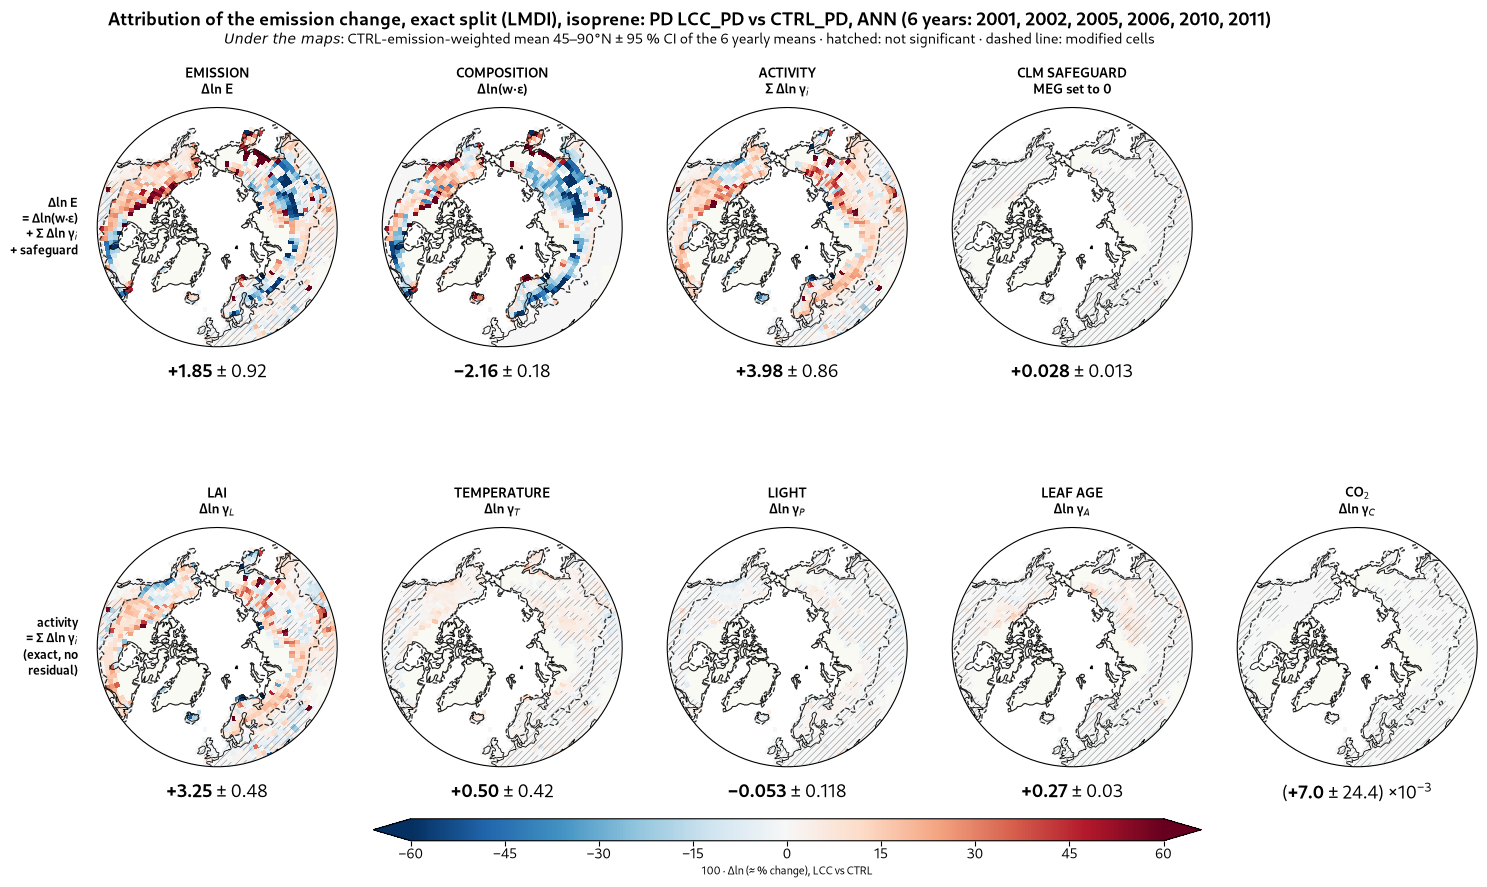

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan-lmdi-attribution-maps/PD_isoprene_attribution_LMDI_JJA_6yr.png


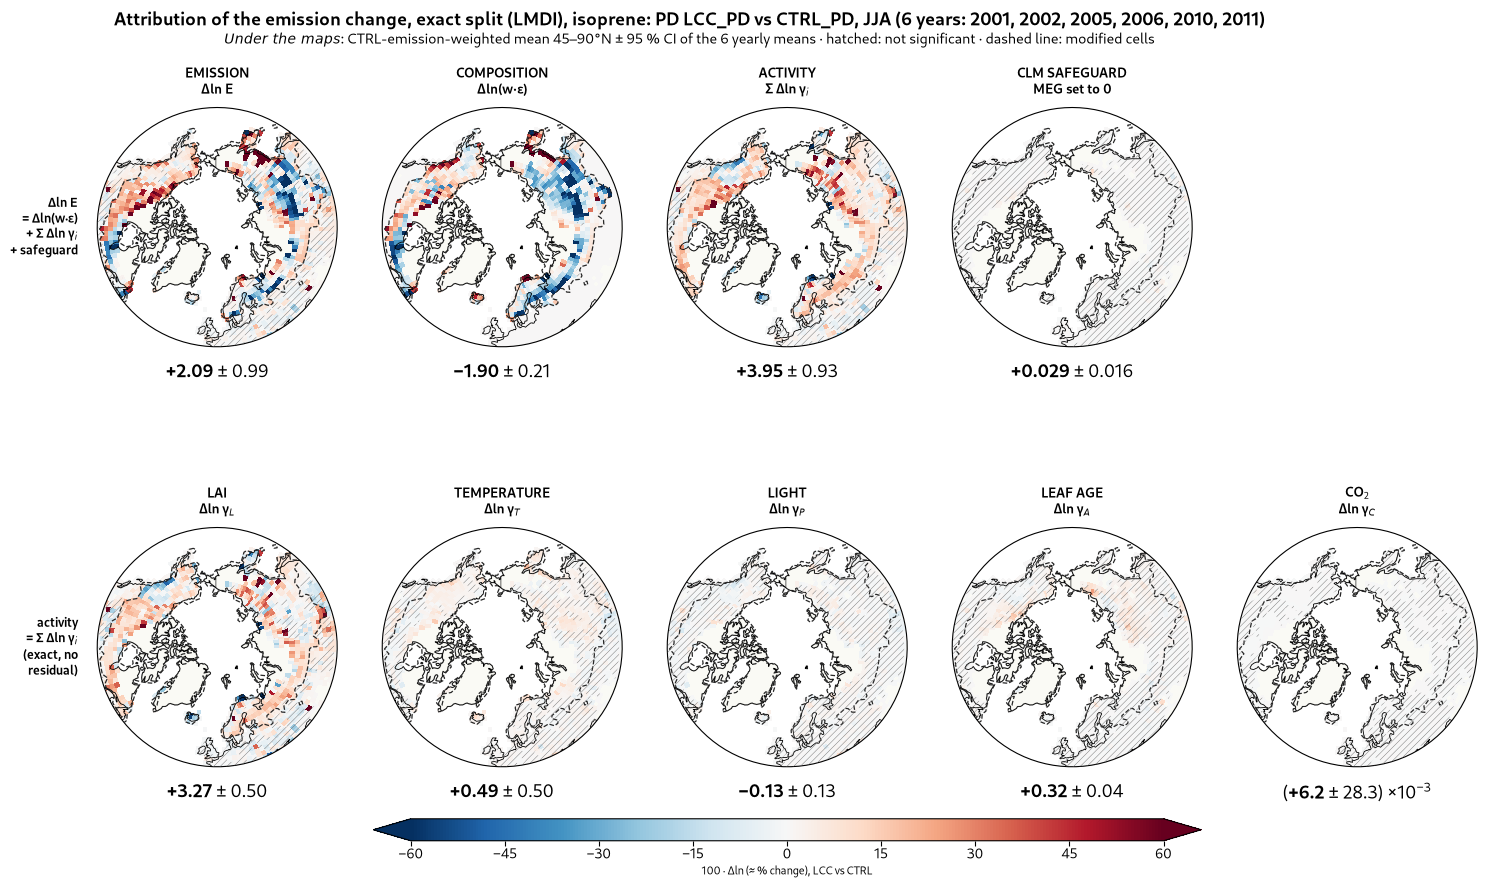

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan-lmdi-attribution-maps/PD_MTERP_attribution_LMDI_ANN_6yr.png


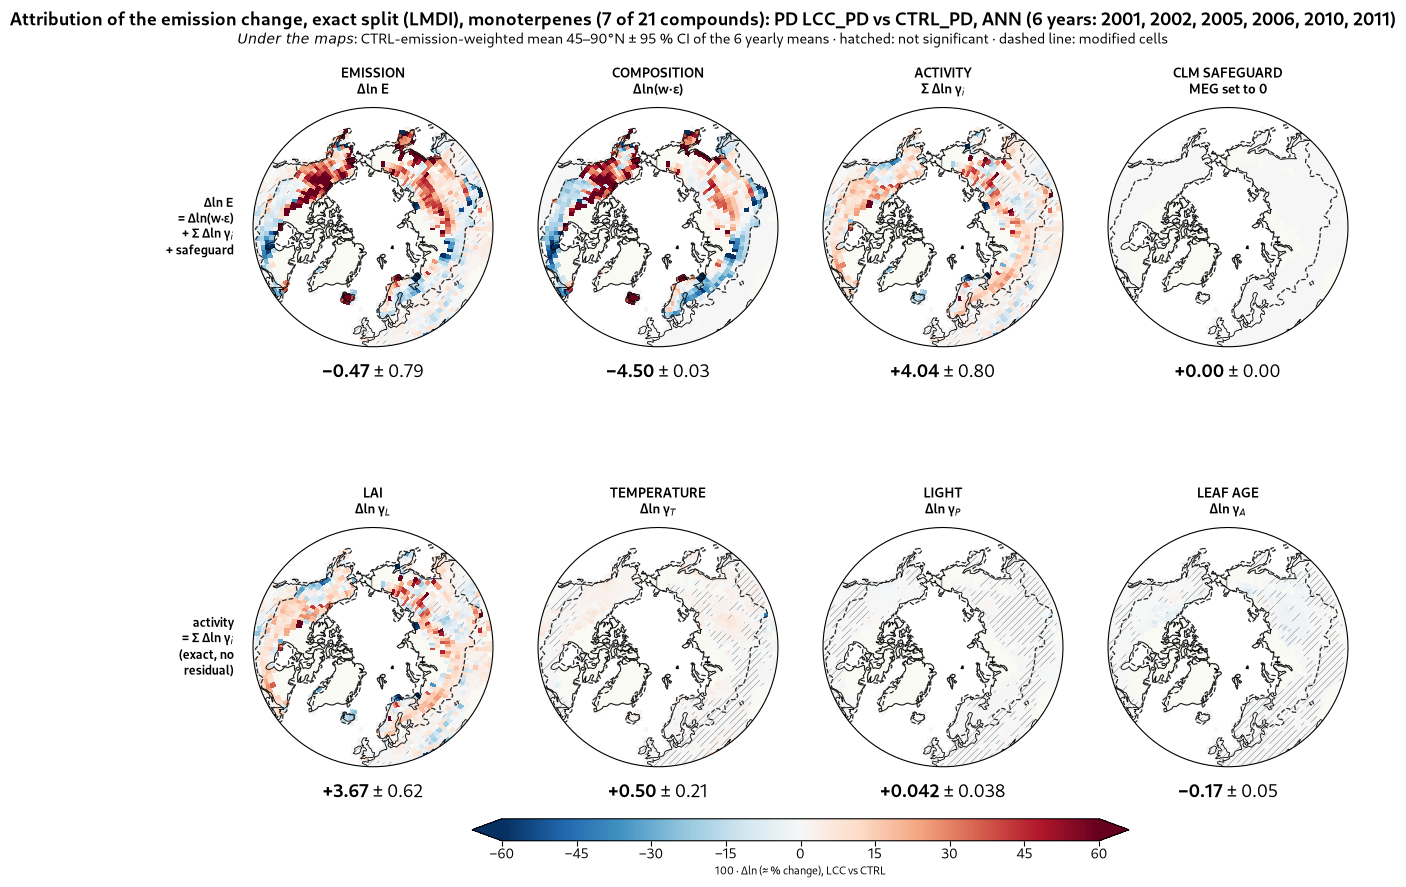

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan-lmdi-attribution-maps/PD_MTERP_attribution_LMDI_JJA_6yr.png


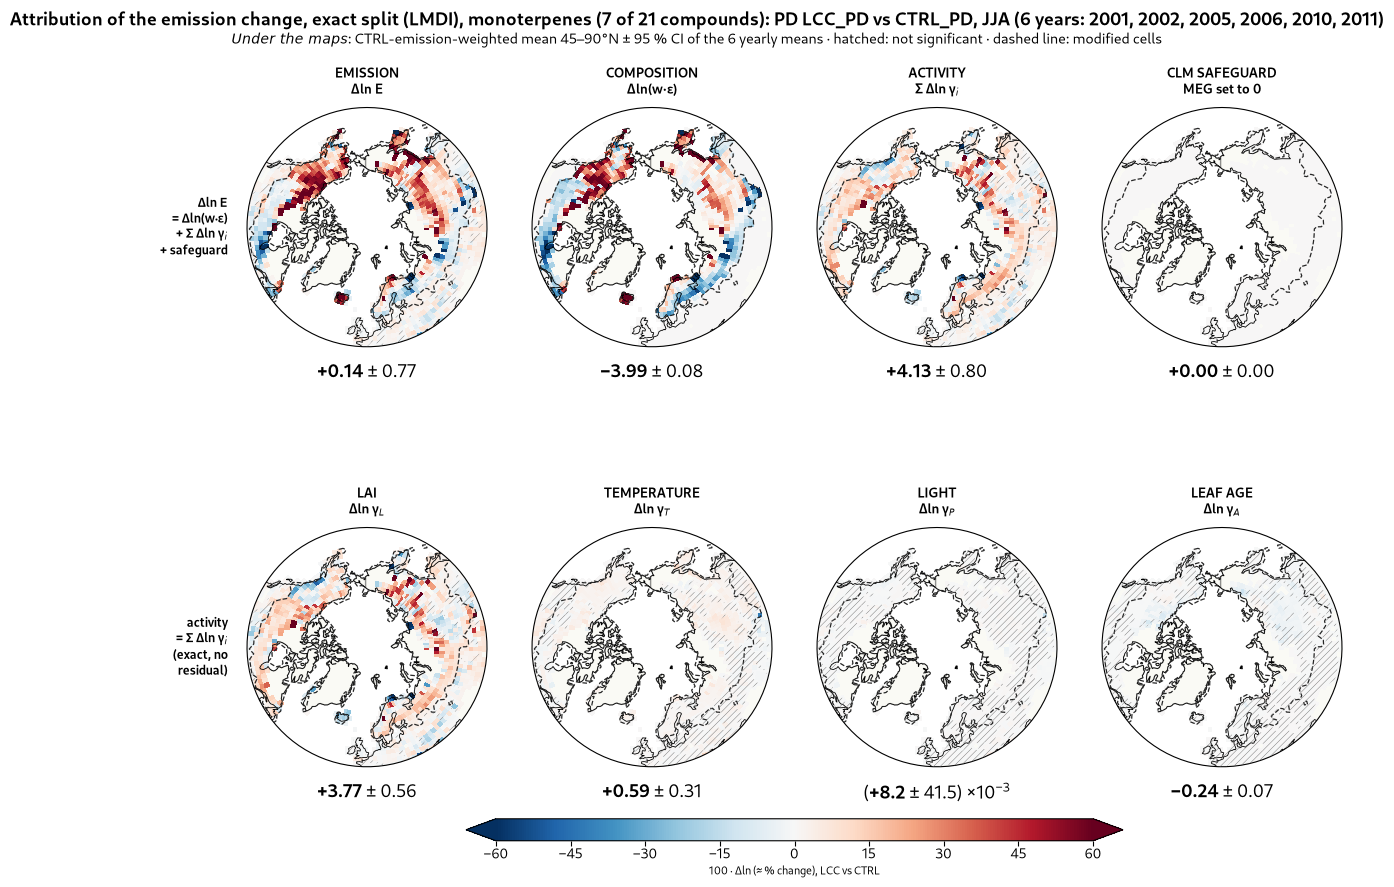

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan-lmdi-attribution-maps/FUT_isoprene_attribution_LMDI_ANN_6yr.png


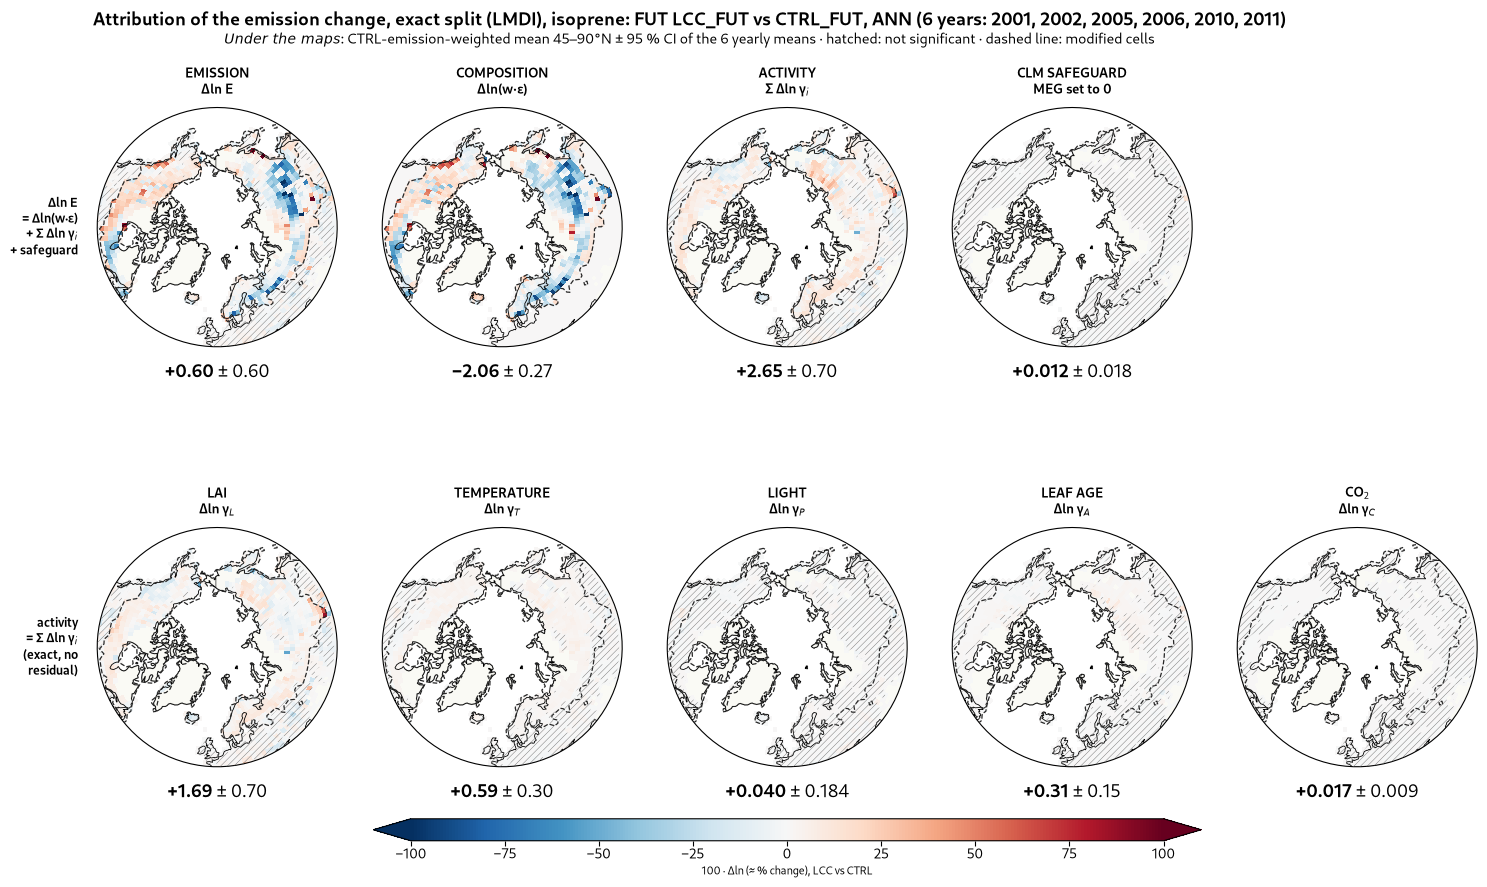

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan-lmdi-attribution-maps/FUT_isoprene_attribution_LMDI_JJA_6yr.png


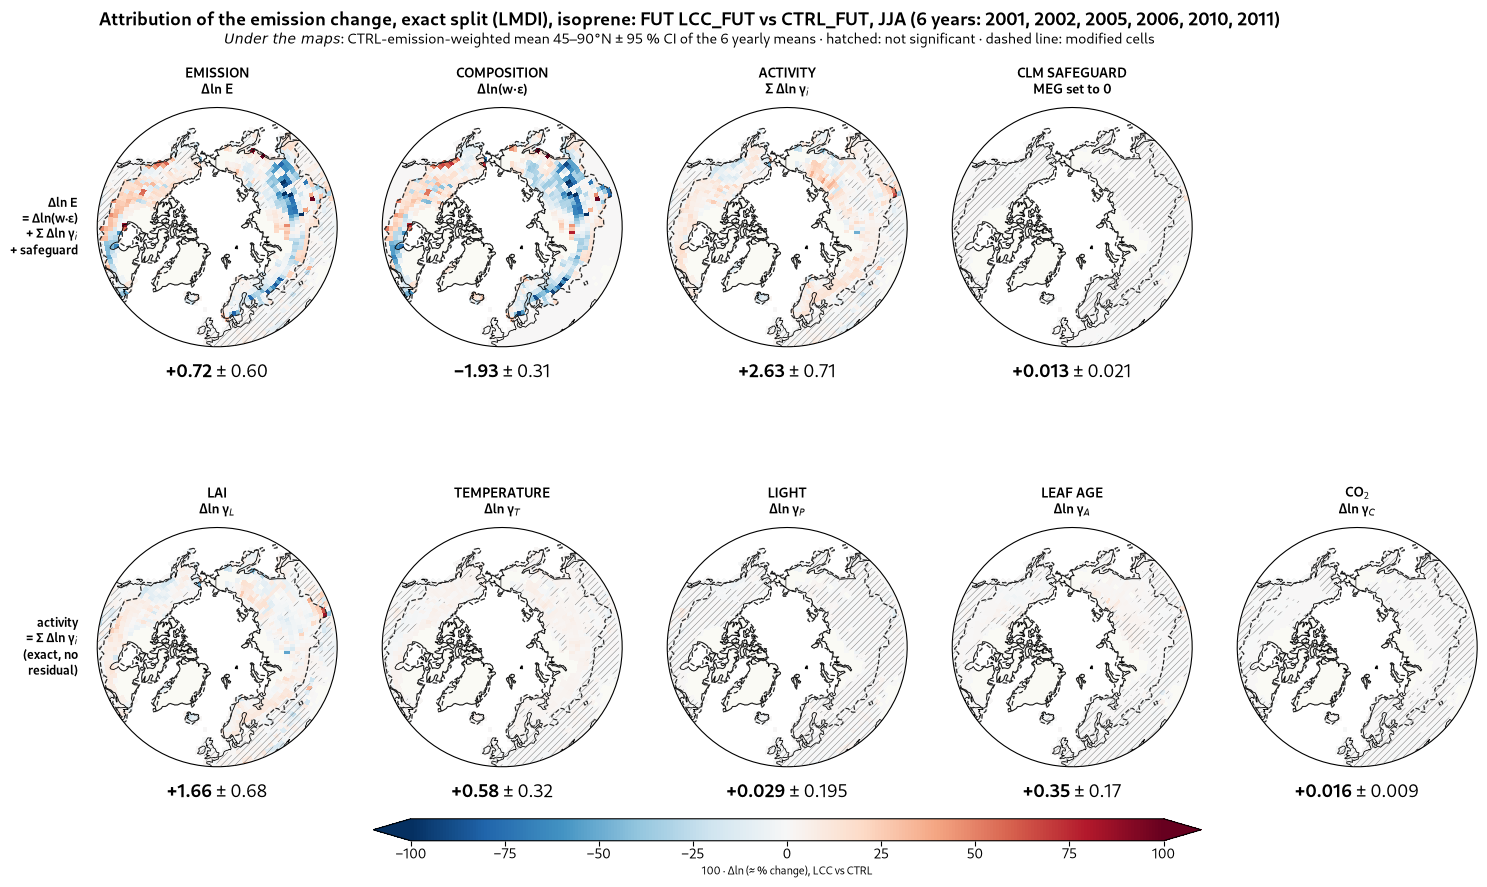

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan-lmdi-attribution-maps/FUT_MTERP_attribution_LMDI_ANN_6yr.png


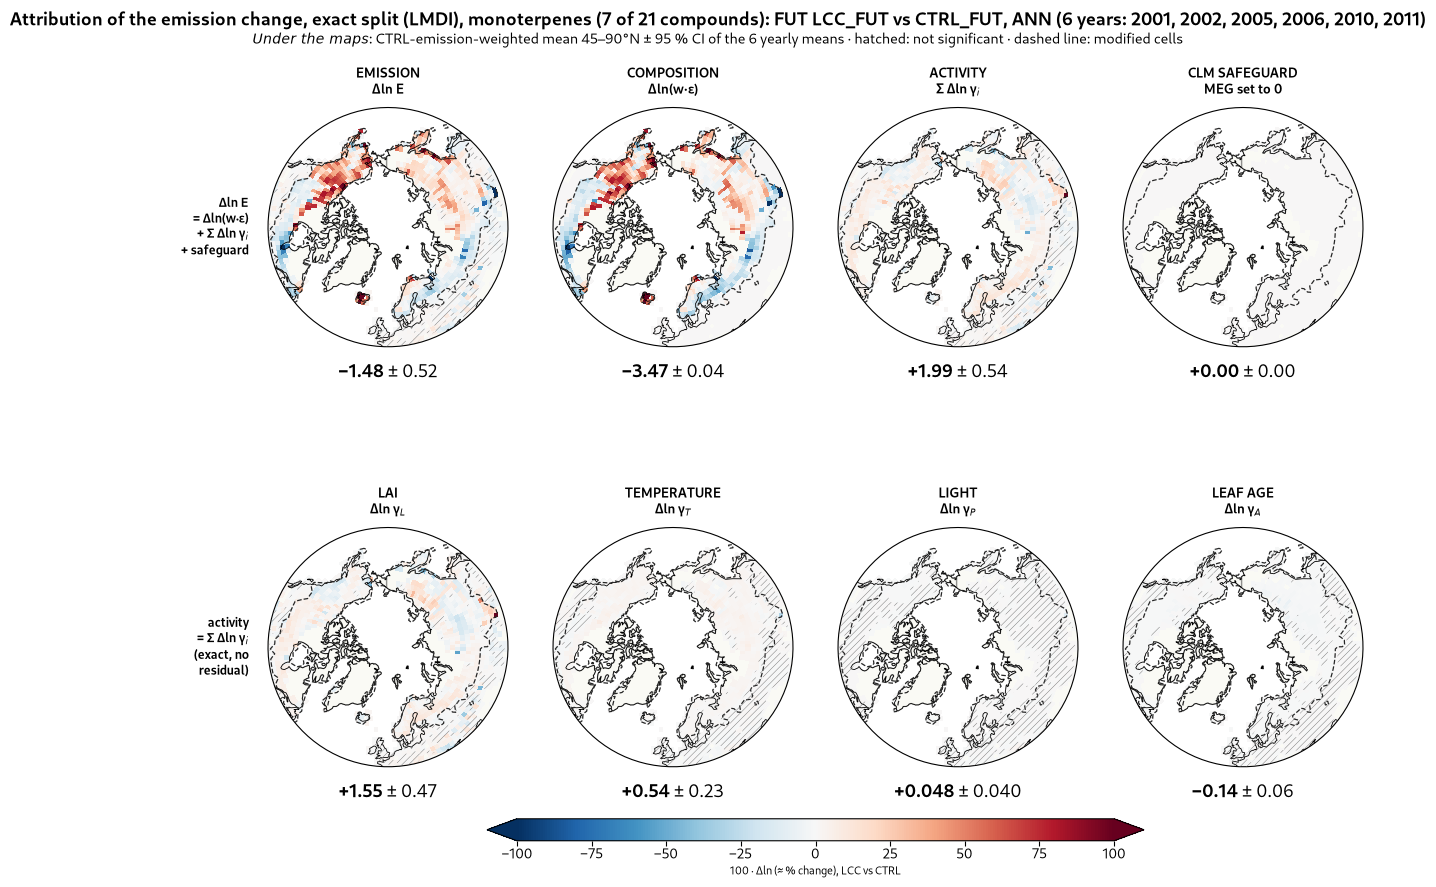

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan-lmdi-attribution-maps/FUT_MTERP_attribution_LMDI_JJA_6yr.png


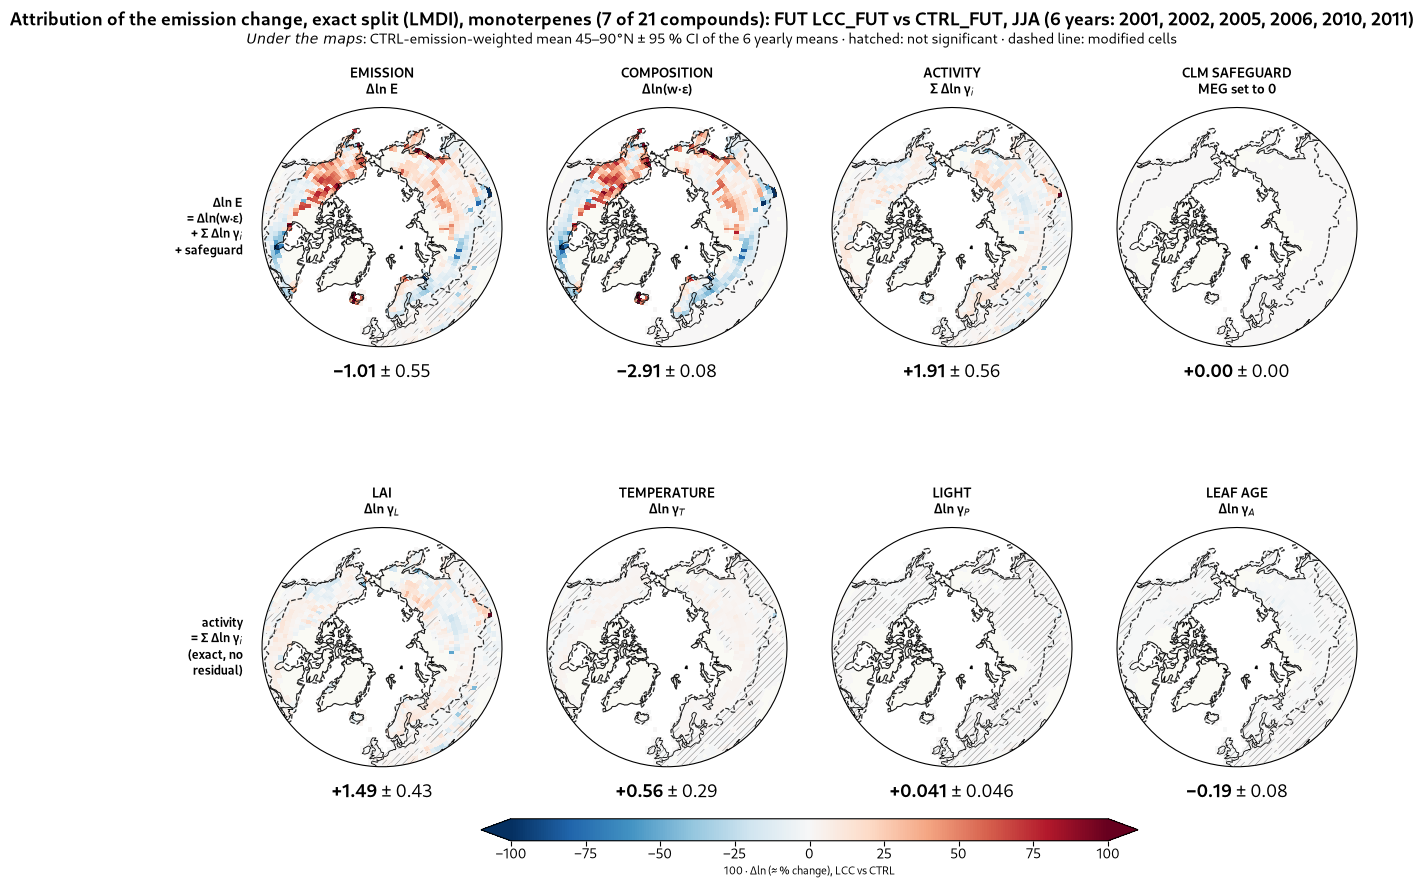

term                                dlnE   composition      activity  \
experiment group    season                                             
PD         isoprene ANN     +1.85 ± 0.92  -2.16 ± 0.18  +3.98 ± 0.86   
                    JJA     +2.09 ± 0.99  -1.90 ± 0.21  +3.95 ± 0.93   
           MTERP    ANN     -0.47 ± 0.79  -4.50 ± 0.03  +4.04 ± 0.80   
                    JJA     +0.14 ± 0.77  -3.99 ± 0.08  +4.13 ± 0.80   
FUT        isoprene ANN     +0.60 ± 0.60  -2.06 ± 0.27  +2.65 ± 0.70   
                    JJA     +0.72 ± 0.60  -1.93 ± 0.31  +2.63 ± 0.71   
           MTERP    ANN     -1.48 ± 0.52  -3.47 ± 0.04  +1.99 ± 0.54   
                    JJA     -1.01 ± 0.55  -2.91 ± 0.08  +1.91 ± 0.56   

term                           safeguard        gammaL        gammaT  \
experiment group    season                                             
PD         isoprene ANN     +0.03 ± 0.01  +3.25 ± 0.48  +0.50 ± 0.42   
                    JJA     +0.03 ± 0.02  +3.27 ± 0.50  +0.49 ± 0.50   
           MTERP    ANN     +0.00 ± 0.00  +3.67 ± 0.62  +0.50 ± 0.21   
                    JJA     +0.00 ± 0.00  +3.77 ± 0.56  +0.59 ± 0.31   
FUT        isoprene ANN     +0.01 ± 0.02  +1.69 ± 0.70  +0.59 ± 0.30   
                    JJA     +0.01 ± 0.02  +1.66 ± 0.68  +0.58 ± 0.32   
           MTERP    ANN     +0.00 ± 0.00  +1.55 ± 0.47  +0.54 ± 0.23   
                    JJA     +0.00 ± 0.00  +1.49 ± 0.43  +0.56 ± 0.29   

term                              gammaP        gammaA        gammaC  
experiment group    season                                            
PD         isoprene ANN     -0.05 ± 0.12  +0.27 ± 0.03  +0.01 ± 0.02  
                    JJA     -0.13 ± 0.13  +0.32 ± 0.04  +0.01 ± 0.03  
           MTERP    ANN     +0.04 ± 0.04  -0.17 ± 0.05           NaN  
                    JJA     +0.01 ± 0.04  -0.24 ± 0.07           NaN  
FUT        isoprene ANN     +0.04 ± 0.18  +0.31 ± 0.15  +0.02 ± 0.01  
                    JJA     +0.03 ± 0.19  +0.35 ± 0.17  +0.02 ± 0.01  
           MTERP    ANN     +0.05 ± 0.04  -0.14 ± 0.06           NaN  
                    JJA     +0.04 ± 0.05  -0.19 ± 0.08           NaN

In [3]:
rows_tab = []
for (exp, group, season), (E0, T) in data.items():
    v, step = mm.ATTRIBUTION_VMAX[exp]
    norm = mcolors.TwoSlopeNorm(vmin=-v, vcenter=0, vmax=v)
    lcc, ctrl = EXPERIMENTS[exp][1:]
    e_ctrl = E0.mean("year")
    thr = MIN_EMISSION_SHARE * float(np.nanquantile(e_ctrl.where(e_ctrl["lat"] >= LAT_MIN).values, 0.98))
    keep = e_ctrl > thr
    w_em = (e_ctrl * np.cos(np.deg2rad(e_ctrl["lat"]))).where(keep, 0)
    mod = mm._modified_mask(e_ctrl)
    gam = [g for g in GAMMAS if group == "isoprene" or g != "gammaC"]
    rows = [["dlnE", "composition", "activity", "safeguard"], gam]
    ncols = max(len(r) for r in rows)
    fig, axes = fm.map_grid(len(rows), ncols, left=2.2, titles_every_row=True)
    for i, keys in enumerate(rows):
        for j in range(ncols):
            if j >= len(keys):
                axes[i, j].set_visible(False)
                continue
            x = T[keys[j]].where(keep)
            m, half = mm._interval(x, w_em, LAT_MIN)
            rows_tab.append(dict(experiment=exp, group=group, season=season, term=keys[j], mean=m, ci95=half))
            p = mm._panel(axes[i, j], x.mean("year"), norm, "RdBu_r", TITLE[keys[j]], LAT_MIN,
                          not_sig=mm._not_significant(x, LAT_MIN, FDR_ALPHA), modified=mod,
                          text=fm._format_interval(m, half))
    mm._row_label(axes[0, 0], "Δln E\n= Δln(w·ε)\n+ Σ Δln γ$_i$\n+ safeguard")
    mm._row_label(axes[1, 0], "activity\n= Σ Δln γ$_i$\n(exact, no\nresidual)")
    cb = fm._cbar_below(fig, axes[-1, :], p, "100 · Δln (≈ % change), LCC vs CTRL", fm.CBAR_LABELSIZE_SHARED, shrink=0.6)
    cb.set_ticks(np.arange(-v, v + step / 2, step))
    mm._title(fig, f"Attribution of the emission change, exact split (LMDI), {mm.GROUP_TITLE[group]}: "
                   f"{exp} {lcc} vs {ctrl}, {season} (6 years: {', '.join(map(str, YEARS))})",
              rf"$\mathit{{Under\ the\ maps}}$: CTRL-emission-weighted mean {LAT_MIN:g}–90°N ± 95 % CI of the 6 yearly means"
              " · hatched: not significant · dashed line: modified cells")
    path = FIG / f"{exp}_{group}_attribution_LMDI_{season}_6yr.png"
    fig.savefig(path, dpi=200, bbox_inches="tight"); print("Saved", path)
    plt.show(); plt.close(fig)

tab = pd.DataFrame(rows_tab)
for exp, t in tab.groupby("experiment", sort=False):
    t.drop(columns="experiment").to_csv(TAB / f"megan_lmdi_attribution_{exp}_45N.csv", index=False)
display(tab.assign(v=lambda t: t["mean"].map("{:+.2f}".format) + " ± " + t["ci95"].map("{:.2f}".format))
           .pivot_table(index=["experiment", "group", "season"], columns="term", values="v", aggfunc="first", sort=False)
           .reindex(columns=list(TITLE)))
